In [2]:

import zipfile
import os

with zipfile.ZipFile('/content/archive (2).zip', 'r') as zip_ref:
    zip_ref.extractall('/content/netflix_data')

os.listdir('/content/netflix_data')


['netflix_titles.csv']

In [4]:

import pandas as pd

df = pd.read_csv('/content/netflix_data/netflix_titles.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Number of rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [5]:

print("DATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

MISSING VALUES
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed

In [6]:

# Fill missing values
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['rating'] = df['rating'].fillna('Unknown')
df['duration'] = df['duration'].fillna('Unknown')

# Convert date_added into date format
df['date_added'] = pd.to_datetime(
    df['date_added'].str.strip(),
    format='mixed',
    errors='coerce'
)

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


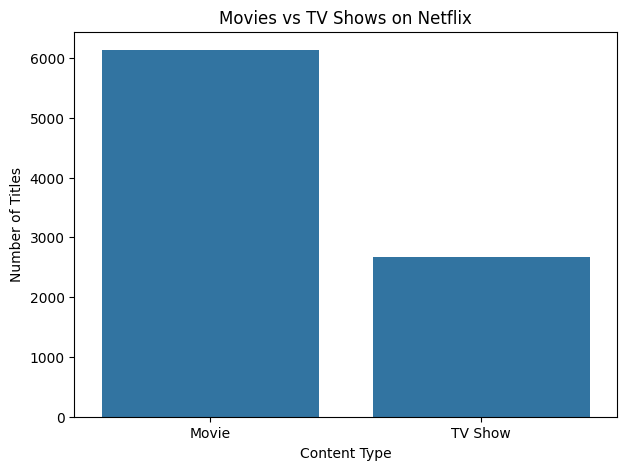

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

content_counts = df['type'].value_counts()

plt.figure(figsize=(7,5))
sns.barplot(x=content_counts.index, y=content_counts.values)

plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.show()


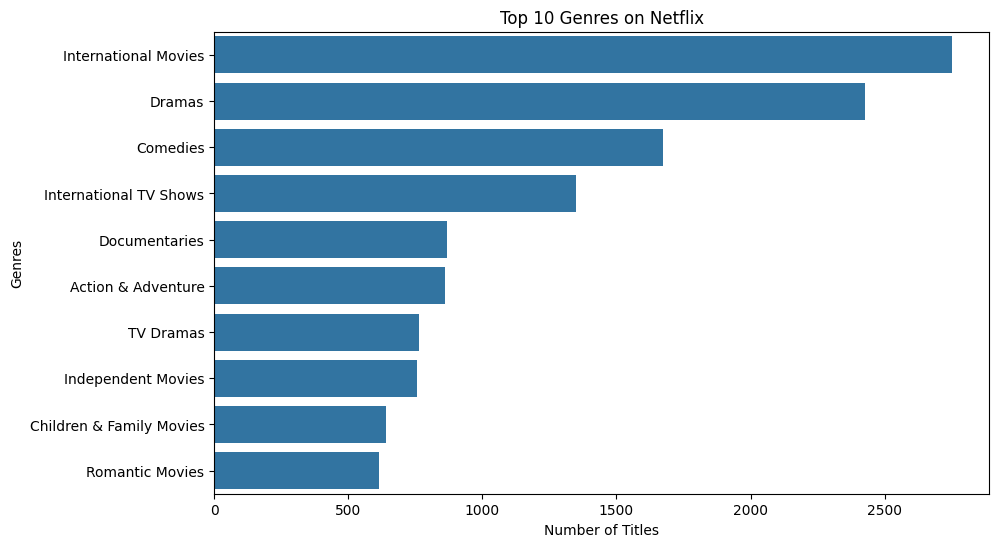

In [8]:

genre_counts = df['listed_in'].str.split(', ').explode().value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)

plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genres')
plt.show()


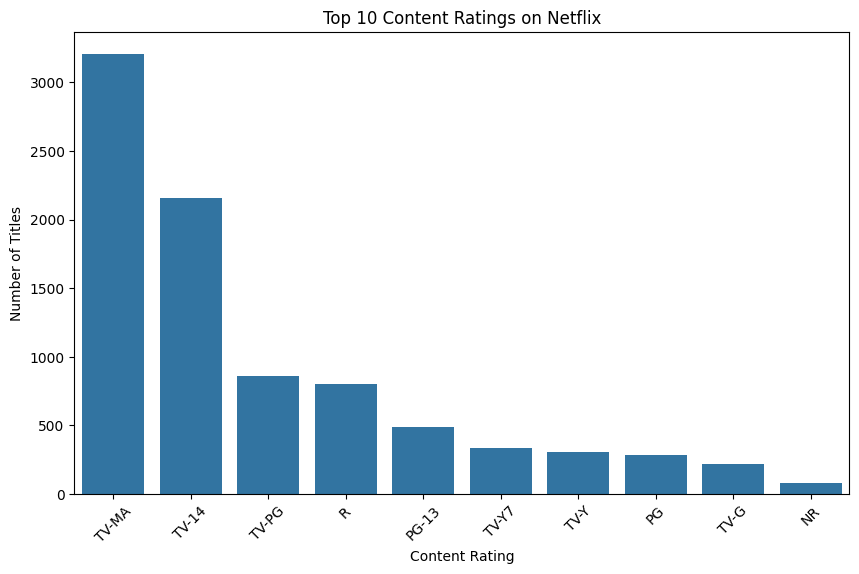

In [9]:

rating_counts = df['rating'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=rating_counts.index, y=rating_counts.values)

plt.title('Top 10 Content Ratings on Netflix')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.show()


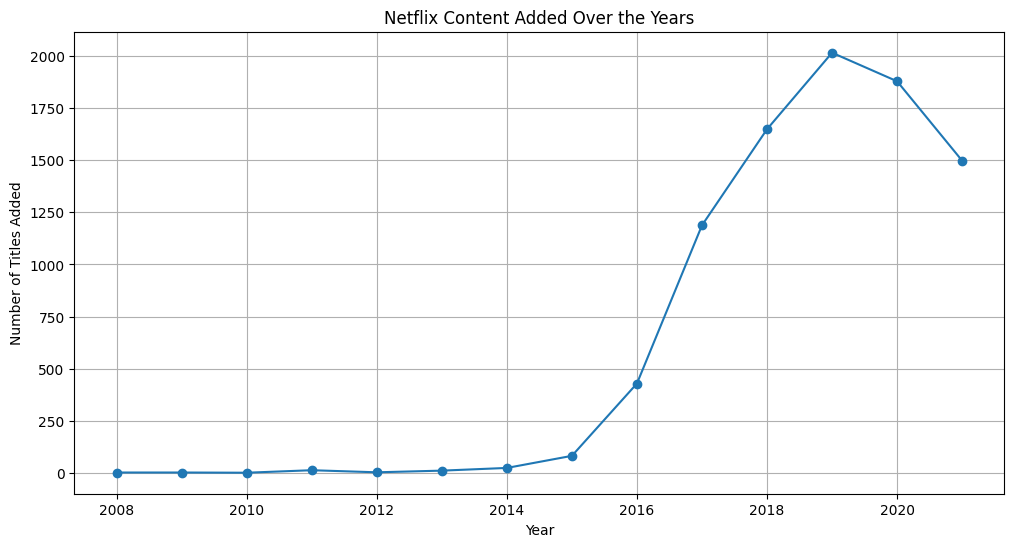

In [10]:

year_counts = df['date_added'].dt.year.value_counts().sort_index()

plt.figure(figsize=(12,6))
plt.plot(year_counts.index, year_counts.values, marker='o')

plt.title('Netflix Content Added Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Titles Added')
plt.grid(True)
plt.show()


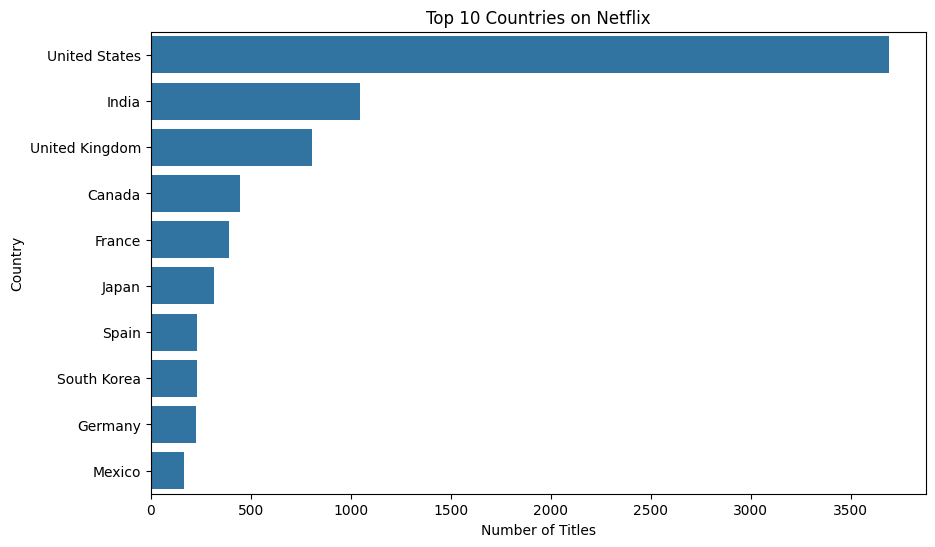

In [11]:

country_counts = df['country'].str.split(', ').explode()
country_counts = country_counts[country_counts != 'Unknown'].value_counts().head(10)

plt.figure(figsize=(10,6))
sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title('Top 10 Countries on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()


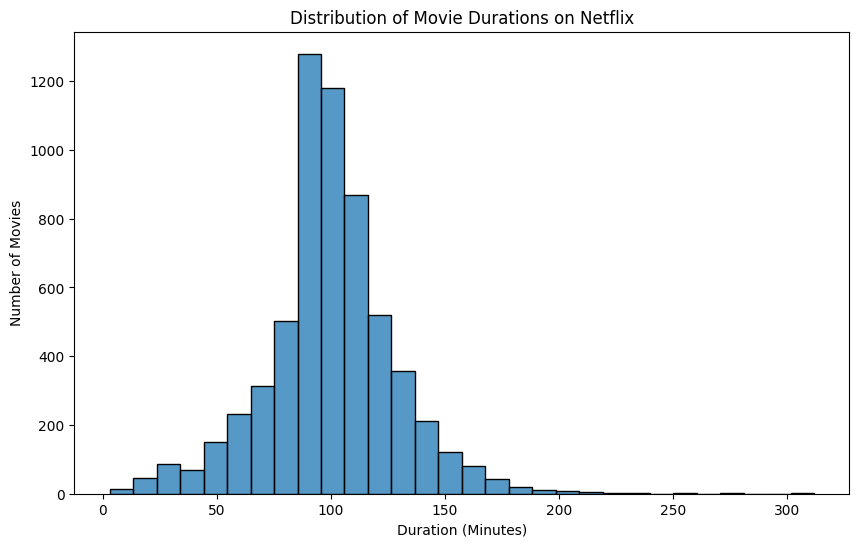

In [12]:

movie_duration = df[df['type'] == 'Movie'].copy()

movie_duration['duration_minutes'] = pd.to_numeric(
    movie_duration['duration'].str.extract(r'(\d+)')[0],
    errors='coerce'
)

plt.figure(figsize=(10,6))
sns.histplot(movie_duration['duration_minutes'].dropna(), bins=30)

plt.title('Distribution of Movie Durations on Netflix')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.show()


In [13]:
import sqlite3

conn = sqlite3.connect('netflix_analysis.db')

df.to_sql('netflix', conn, if_exists='replace', index=False)

print("Netflix data successfully stored in SQL!")

Netflix data successfully stored in SQL!


In [14]:

queries = {
    "Query 1: Movies vs TV Shows": """
        SELECT type, COUNT(*) AS total_titles
        FROM netflix
        GROUP BY type;
    """,

    "Query 2: Top 10 Countries": """
        SELECT country, COUNT(*) AS total_titles
        FROM netflix
        WHERE country != 'Unknown'
        GROUP BY country
        ORDER BY total_titles DESC
        LIMIT 10;
    """,

    "Query 3: Top 10 Content Categories": """
        SELECT listed_in, COUNT(*) AS total_titles
        FROM netflix
        GROUP BY listed_in
        ORDER BY total_titles DESC
        LIMIT 10;
    """,

    "Query 4: Content Ratings": """
        SELECT rating, COUNT(*) AS total_titles
        FROM netflix
        GROUP BY rating
        ORDER BY total_titles DESC;
    """,

    "Query 5: Content by Release Year": """
        SELECT release_year, COUNT(*) AS total_titles
        FROM netflix
        GROUP BY release_year
        ORDER BY release_year DESC
        LIMIT 10;
    """
}

for title, query in queries.items():
    print("\n", title)
    display(pd.read_sql_query(query, conn))



 Query 1: Movies vs TV Shows


,type,total_titles
0,Movie,6131
1,TV Show,2676



 Query 2: Top 10 Countries


,country,total_titles
0,United States,2818
1,India,972
2,United Kingdom,419
3,Japan,245
4,South Korea,199
5,Canada,181
6,Spain,145
7,France,124
8,Mexico,110
9,Egypt,106



 Query 3: Top 10 Content Categories


,listed_in,total_titles
0,"Dramas, International Movies",362
1,Documentaries,359
2,Stand-Up Comedy,334
3,"Comedies, Dramas, International Movies",274
4,"Dramas, Independent Movies, International Movies",252
5,Kids' TV,220
6,Children & Family Movies,215
7,"Children & Family Movies, Comedies",201
8,"Documentaries, International Movies",186
9,"Dramas, International Movies, Romantic Movies",180



 Query 4: Content Ratings


,rating,total_titles
0,TV-MA,3207
1,TV-14,2160
2,TV-PG,863
3,R,799
4,PG-13,490
5,TV-Y7,334
6,TV-Y,307
7,PG,287
8,TV-G,220
9,NR,80



 Query 5: Content by Release Year


,release_year,total_titles
0,2021,592
1,2020,953
2,2019,1030
3,2018,1147
4,2017,1032
5,2016,902
6,2015,560
7,2014,352
8,2013,288
9,2012,237


In [15]:

# Insight 1: Most popular content type
print("1. CONTENT TYPE")
print(df['type'].value_counts())

# Insight 2: Most common genres
print("\n2. TOP 5 GENRES")
genres = df['listed_in'].str.split(', ').explode()
print(genres.value_counts().head(5))

# Insight 3: Top content-producing countries
print("\n3. TOP 5 COUNTRIES")
countries = df['country'].str.split(', ').explode()
countries = countries[countries != 'Unknown']
print(countries.value_counts().head(5))

# Additional rating analysis
print("\n4. TOP CONTENT RATINGS")
print(df['rating'].value_counts().head(5))


1. CONTENT TYPE
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

2. TOP 5 GENRES
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

3. TOP 5 COUNTRIES
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

4. TOP CONTENT RATINGS
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64
